# Alzheimer’s MRI Classification — TensorFlow / Keras

This notebook consolidates the supplied CNN approaches into one TensorFlow project:
1. `AlzheimerCNN`: the four-stage CNN structure from **Clinical Base Model.ipynb**, re-created in Keras.
2. `SequentialCNN128`: the original 32/64/128-filter CNN from **04_cnn_model.ipynb**.
3. Transfer learning with **EfficientNetB0** and **ResNet50**.
4. Validation-based hyperparameter experiments, training curves, classification reports, confusion matrices, a final comparison table, and model export.

**Dataset folder:** `combined_images/` with `MildDemented`, `ModerateDemented`, `NonDemented`, and `VeryMildDemented` subfolders.

## Important GPU note for your AMD Radeon integrated GPU

`device = torch_directml.device()` is **PyTorch-only**. TensorFlow cannot use that device object. This notebook detects TensorFlow GPU devices with `tf.config.list_physical_devices('GPU')` and uses one if TensorFlow can access it; otherwise it runs on CPU.

On Windows, ordinary TensorFlow installations often do not support GPU acceleration on AMD integrated Radeon graphics. If no GPU is detected, the notebook will still work on your Ryzen 7 CPU. Do not install PyTorch DirectML expecting it to accelerate TensorFlow.

Start with `QUICK_RUN = True` to verify the pipeline. Use `False` for the full experiment. Training results are not pre-filled; run the notebook to obtain real metrics.

## 1. Imports, configuration, and TensorFlow device detection

In [1]:
import os, sys, time, json, random, platform, gc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Platform:", platform.platform())
print("TensorFlow physical GPUs:", tf.config.list_physical_devices("GPU"))

# If TensorFlow sees a GPU, allow memory growth.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Could not set memory growth:", e)

# Dataset location: Home/Desktop/Alzheimer
IMAGE_DIR = Path.home() / "Desktop" / "Alzheimer"

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {IMAGE_DIR}. "
        "Check that the Alzheimer folder is inside your Desktop."
    )

OUTPUT_DIR = IMAGE_DIR.parent / "Outputs_TensorFlow"
MODEL_DIR = OUTPUT_DIR / "cnn_experiments"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["MildDemented", "ModerateDemented", "NonDemented", "VeryMildDemented"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
# Full training configuration. Set QUICK_RUN=True only for a short pipeline test.
IMAGE_SIZE = 224
BATCH_SIZE = 32
QUICK_RUN = False
EPOCHS = 2 if QUICK_RUN else 40
EARLY_STOPPING_PATIENCE = 2 if QUICK_RUN else 7
VALIDATION_SIZE = 0.15
TEST_SIZE = 0.15
MAX_IMAGES_QUICK = 2500 if QUICK_RUN else None
AUTOTUNE = tf.data.AUTOTUNE

print("Image directory:", IMAGE_DIR)
print("Output directory:", OUTPUT_DIR)
print("Visible GPU:", bool(tf.config.list_physical_devices("GPU")))
print("Training backend: TensorFlow GPU if available; otherwise CPU.")

Python: 3.10.11
TensorFlow: 2.16.1
Platform: Windows-10-10.0.26300-SP0
TensorFlow physical GPUs: []
Image directory: C:\Users\Tanmay\code\Alzheimer Project Final\combined_images
Output directory: C:\Users\Tanmay\code\Alzheimer Project Final\Outputs_TensorFlow
Visible GPU: False
Training backend: TensorFlow GPU if available; otherwise CPU.


## 2. Inspect dataset and create a stratified split

Total images: 44000


,image_count
label,
MildDemented,10000
ModerateDemented,10000
NonDemented,12800
VeryMildDemented,11200


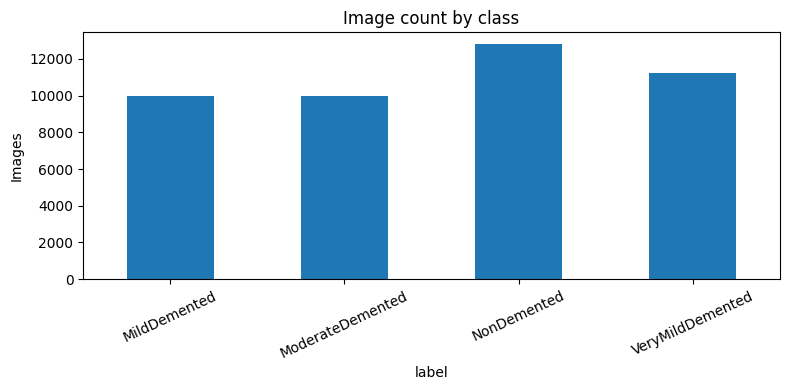

Train: 30800 | Validation: 6600 | Test: 6600


split,test,train,validation
label,,,
MildDemented,1500,7000,1500
ModerateDemented,1500,7000,1500
NonDemented,1920,8960,1920
VeryMildDemented,1680,7840,1680


Caution: this is a stratified image-level split. If multiple images/slices belong to the same patient, use patient-level group splitting to prevent leakage.


In [2]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
records = []
for class_name in CLASS_NAMES:
    class_dir = IMAGE_DIR / class_name
    if not class_dir.is_dir():
        print("WARNING: missing class directory:", class_dir)
        continue
    for p in class_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            records.append({"image_path": str(p.resolve()), "label": class_name})

manifest = pd.DataFrame(records)
if manifest.empty:
    raise RuntimeError("No images found. Check the folder path and class subfolders.")
if set(manifest.label.unique()) != set(CLASS_NAMES):
    raise ValueError(f"Expected all four classes. Found: {sorted(manifest.label.unique())}")

print("Total images:", len(manifest))
display(manifest["label"].value_counts().reindex(CLASS_NAMES).rename("image_count").to_frame())
manifest["label"].value_counts().reindex(CLASS_NAMES).plot(kind="bar", figsize=(8,4), title="Image count by class")
plt.ylabel("Images"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

# Quick mode uses a stratified subset to test that all cells work.
source_df = manifest.copy()
if MAX_IMAGES_QUICK and len(source_df) > MAX_IMAGES_QUICK:
    source_df, _ = train_test_split(source_df, train_size=MAX_IMAGES_QUICK,
                                    stratify=source_df["label"], random_state=SEED)
    print(f"QUICK RUN: using a stratified sample of {len(source_df):,} images.")

trainval_df, test_df = train_test_split(
    source_df, test_size=TEST_SIZE, stratify=source_df["label"], random_state=SEED
)
train_df, val_df = train_test_split(
    trainval_df, test_size=VALIDATION_SIZE/(1-TEST_SIZE),
    stratify=trainval_df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))
display(pd.concat([
    train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")
]).pivot_table(index="label", columns="split", values="image_path", aggfunc="count").reindex(CLASS_NAMES))

split_manifest = pd.concat([
    train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")
], ignore_index=True)
split_manifest.to_csv(OUTPUT_DIR / "mri_split_manifest.csv", index=False)

print("Caution: this is a stratified image-level split. If multiple images/slices belong to the same patient, use patient-level group splitting to prevent leakage.")

## 3. TensorFlow input pipelines and augmentation

In [3]:
def decode_image(path, label, channels=3, training=False, normalize="zero_one"):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=channels, expand_animations=False)
    image.set_shape([None, None, channels])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)
    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=0.05)
        image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    if normalize == "gray_minus_one_one":
        image = image / 127.5 - 1.0
    elif normalize == "imagenet":
        image = keras.applications.resnet50.preprocess_input(image)
    elif normalize == "raw_255":
        # EfficientNetB0 Keras includes its own rescaling layer; keep pixels in [0,255].
        image = image
    else:
        image = image / 255.0
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, channels=3, training=False, normalize="zero_one"):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(CLASS_TO_IDX).astype("int32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda p, y: decode_image(p, y, channels=channels, training=training, normalize=normalize),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

# The first custom model uses one grayscale channel. The second CNN and transfer models use RGB.
gray_train_ds = make_dataset(train_df, channels=1, training=True, normalize="gray_minus_one_one")
gray_val_ds = make_dataset(val_df, channels=1, training=False, normalize="gray_minus_one_one")
gray_test_ds = make_dataset(test_df, channels=1, training=False, normalize="gray_minus_one_one")

rgb_train_ds = make_dataset(train_df, channels=3, training=True, normalize="zero_one")
rgb_val_ds = make_dataset(val_df, channels=3, training=False, normalize="zero_one")
rgb_test_ds = make_dataset(test_df, channels=3, training=False, normalize="zero_one")

# ImageNet preprocessing expects pixel values in 0..255 before preprocess_input.
rgb_imagenet_train_ds = make_dataset(train_df, channels=3, training=True, normalize="imagenet")
rgb_imagenet_val_ds = make_dataset(val_df, channels=3, training=False, normalize="imagenet")
rgb_imagenet_test_ds = make_dataset(test_df, channels=3, training=False, normalize="imagenet")
rgb_raw_train_ds = make_dataset(train_df, channels=3, training=True, normalize="raw_255")
rgb_raw_val_ds = make_dataset(val_df, channels=3, training=False, normalize="raw_255")
rgb_raw_test_ds = make_dataset(test_df, channels=3, training=False, normalize="raw_255")

for x, y in gray_train_ds.take(1):
    print("Gray batch:", x.shape, y.shape, "| label IDs:", y[:8].numpy())
for x, y in rgb_train_ds.take(1):
    print("RGB batch:", x.shape, y.shape)

Gray batch: (32, 224, 224, 1) (32,) | label IDs: [0 3 1 2 2 2 1 2]
RGB batch: (32, 224, 224, 3) (32,)


## 4. Model 1 — `AlzheimerCNN` from Clinical Base Model notebook

In [4]:
def build_alzheimer_cnn(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 1), num_classes=4, dropout_rate=0.4):
    """Keras equivalent of the source CNN: 16/32/64/128 filters, BN, ReLU, pooling, GAP, dropout."""
    inputs = keras.Input(shape=input_shape)
    x = layers.Conv2D(16, 3, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="AlzheimerCNN")

def compile_model(model, learning_rate=1e-3):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def callbacks_for(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(
            filepath=str(MODEL_DIR / f"{name}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=0
        )
    ]

# Validate the grayscale dataset shape before building/training the model.
for _images, _labels in gray_train_ds.take(1):
    expected_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, 1)
    print("Grayscale batch shape:", _images.shape)
    if _images.shape.rank != 4 or _images.shape[1:] != (IMAGE_SIZE, IMAGE_SIZE, 1):
        raise ValueError(
            f"Expected grayscale images shaped (batch, {IMAGE_SIZE}, {IMAGE_SIZE}, 1), "
            f"but received {_images.shape}. Check the gray dataset pipeline."
        )

model1 = compile_model(build_alzheimer_cnn(dropout_rate=0.4))
model1.summary()
history1 = model1.fit(
    gray_train_ds, validation_data=gray_val_ds, epochs=EPOCHS,
    callbacks=callbacks_for("alzheimer_cnn"), verbose=1
)

Grayscale batch shape: (32, 224, 224, 1)


Model: "AlzheimerCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 98,388 (384.33 KB)

 Trainable params: 97,908 (382.45 KB)

 Non-trainable params: 480 (1.88 KB)

Epoch 1/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 518s 535ms/step - accuracy: 0.4708 - loss: 1.1320 - val_accuracy: 0.5194 - val_loss: 1.0608
Epoch 2/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 524s 544ms/step - accuracy: 0.5814 - loss: 0.9069 - val_accuracy: 0.5952 - val_loss: 0.8889
Epoch 3/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 532s 552ms/step - accuracy: 0.6199 - loss: 0.8130 - val_accuracy: 0.6129 - val_loss: 0.7764
Epoch 4/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 526s 546ms/step - accuracy: 0.6404 - loss: 0.7584 - val_accuracy: 0.4282 - val_loss: 1.7401
Epoch 5/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 533s 553ms/step - accuracy: 0.6585 - loss: 0.7254 - val_accuracy: 0.4768 - val_loss: 3.3793
Epoch 6/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 532s 552ms/step - accuracy: 0.6682 - loss: 0.7029 - val_accuracy: 0.6159 - val_loss: 0.8521
Epoch 7/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 517s 537ms/step - accuracy: 0.6829 - loss: 0.6748 - val_accuracy: 0.5374 - val_loss: 1.3382
Epoch 8/40
963/963 ━━━━━━━━━━━━━━━━━━━━ 517s 537ms/step - accuracy: 0.6929 -

## 5. Model 2 — `SequentialCNN128` from 04_cnn_model.ipynb

In [ ]:
def tuned_model_cnn():

    model = models.Sequential([
        layers.Input(shape=(128, 128, 3)),

        # Block 1
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(4, activation='softmax')
    ])

    # Compile the model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# Create the CNN model
model = build_cnn_model()

# Display model architecture
model.summary()


Model: "SequentialCNN128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │       401,412 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 688,420 (2.63 MB)

 Trainable params: 688,420 (2.63 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
 32/963 ━━━━━━━━━━━━━━━━━━━━ 32:18 2s/step - accuracy: 0.2871 - loss: 1.3946

## 6. Transfer learning — EfficientNetB0 and ResNet50

In [ ]:
def build_transfer_model(model_name, input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), num_classes=4, freeze_backbone=True):
    inputs = keras.Input(shape=input_shape)
    if model_name == "EfficientNetB0":
        # Keras EfficientNet includes input rescaling internally; use RGB pixel values in [0,255].
        base = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        x = base(inputs, training=False)
    elif model_name == "ResNet50":
        # ResNet50 preprocess_input is applied by the dataset pipeline.
        base = keras.applications.ResNet50(
            include_top=False, weights="imagenet", input_shape=input_shape
        )
        x = base(inputs, training=False)
    else:
        raise ValueError("model_name must be EfficientNetB0 or ResNet50")
    base.trainable = not freeze_backbone
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=model_name)
    return model, base

transfer_models = {}
transfer_histories = {}
transfer_configs = [
    ("EfficientNetB0", rgb_raw_train_ds, rgb_raw_val_ds),
    ("ResNet50", rgb_imagenet_train_ds, rgb_imagenet_val_ds)
]
for model_name, tr_ds, va_ds in transfer_configs:
    try:
        transfer_model, backbone = build_transfer_model(model_name, freeze_backbone=True)
        compile_model(transfer_model, learning_rate=1e-3)
        print("\nTraining", model_name)
        transfer_model.summary()
        hist = transfer_model.fit(
            tr_ds, validation_data=va_ds, epochs=EPOCHS,
            callbacks=callbacks_for(model_name.lower()), verbose=1
        )
        transfer_models[model_name] = transfer_model
        transfer_histories[model_name] = hist
    except Exception as e:
        print(f"Could not train {model_name}: {e}")
        print("Check internet access for ImageNet weights and your TensorFlow/Keras installation.")
    gc.collect()

## 7. Hyperparameter tuning for the custom CNN

In [ ]:
# Small validation-only grid. QUICK_RUN limits the number of trials for a smoke test.
tuning_grid = [
    {"learning_rate": 1e-3, "dropout_rate": 0.3},
    {"learning_rate": 3e-4, "dropout_rate": 0.4},
    {"learning_rate": 1e-4, "dropout_rate": 0.5},
]
if QUICK_RUN:
    tuning_grid = tuning_grid[:2]

tuning_rows = []
tuning_models = {}
for i, cfg in enumerate(tuning_grid, start=1):
    print(f"\nTrial {i}/{len(tuning_grid)}:", cfg)
    trial_model = compile_model(
        build_alzheimer_cnn(dropout_rate=cfg["dropout_rate"]),
        learning_rate=cfg["learning_rate"]
    )
    trial_hist = trial_model.fit(
        gray_train_ds, validation_data=gray_val_ds, epochs=EPOCHS,
        callbacks=callbacks_for(f"tuning_trial_{i}"), verbose=1
    )
    best_idx = int(np.argmin(trial_hist.history["val_loss"]))
    best_val_loss = float(trial_hist.history["val_loss"][best_idx])
    best_val_acc = float(trial_hist.history["val_accuracy"][best_idx])
    tuning_rows.append({
        "trial": i, **cfg, "best_epoch": best_idx + 1,
        "val_loss": best_val_loss, "val_accuracy": best_val_acc
    })
    tuning_models[i] = trial_model
    del trial_model
    gc.collect()

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["val_accuracy", "val_loss"], ascending=[False, True]
)
display(tuning_df)
tuning_df.to_csv(MODEL_DIR / "hyperparameter_tuning_results.csv", index=False)

## 8. Learning curves

In [ ]:
all_histories = {
    "AlzheimerCNN": history1,
    "SequentialCNN128": history2,
    **transfer_histories
}
fig, axes = plt.subplots(1, 2, figsize=(15,5))
for name, hist in all_histories.items():
    h = hist.history
    axes[0].plot(h.get("loss", []), label=f"{name} train")
    axes[0].plot(h.get("val_loss", []), linestyle="--", label=f"{name} val")
    axes[1].plot(h.get("accuracy", []), label=f"{name} train")
    axes[1].plot(h.get("val_accuracy", []), linestyle="--", label=f"{name} val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.grid(alpha=0.25); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Evaluate all models on the held-out test split

In [ ]:
# Do not use test metrics to select hyperparameters. This cell evaluates candidates after training.
candidate_models = {
    "AlzheimerCNN": (model1, gray_test_ds),
    "SequentialCNN128": (model2, rgb_test_ds),
}
for name, model in transfer_models.items():
    test_ds = rgb_raw_test_ds if name == "EfficientNetB0" else rgb_imagenet_test_ds
    candidate_models[name] = (model, test_ds)

if not tuning_df.empty:
    best_trial_id = int(tuning_df.iloc[0]["trial"])
    best_tuned_model = tuning_models[best_trial_id]
    candidate_models["AlzheimerCNN_Tuned"] = (best_tuned_model, gray_test_ds)
    print("Best tuning config:", tuning_df.iloc[0].to_dict())

test_rows = []
predictions = {}
for name, (model, test_ds) in candidate_models.items():
    eval_values = model.evaluate(test_ds, verbose=0)
    loss, accuracy = float(eval_values[0]), float(eval_values[1])
    y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0
    )
    test_rows.append({
        "model": name, "test_loss": loss, "test_accuracy": accuracy,
        "test_precision_weighted": precision, "test_recall_weighted": recall,
        "test_f1_weighted": f1, "parameters": model.count_params()
    })
    predictions[name] = {"y_true": y_true, "y_pred": y_pred, "probabilities": probs}
    print(f"\n{name} | test accuracy={accuracy:.3%}")
    print(classification_report(
        y_true, y_pred, labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES, digits=4, zero_division=0
    ))
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(6,5))
    disp.plot(ax=ax, xticks_rotation=35, colorbar=False)
    ax.set_title(f"{name} — test confusion matrix")
    plt.tight_layout(); plt.show()

test_results_df = pd.DataFrame(test_rows)

## 10. Results comparison table and test accuracy graph

In [ ]:
comparison_df = test_results_df.sort_values("test_accuracy", ascending=False).reset_index(drop=True)
display(comparison_df.style.format({
    "test_loss":"{:.4f}", "test_accuracy":"{:.2%}",
    "test_precision_weighted":"{:.2%}", "test_recall_weighted":"{:.2%}",
    "test_f1_weighted":"{:.2%}", "parameters":"{:,.0f}"
}))
comparison_df.to_csv(MODEL_DIR / "model_comparison.csv", index=False)

plt.figure(figsize=(10,5))
plt.bar(comparison_df["model"], comparison_df["test_accuracy"])
plt.title("Held-out test accuracy comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print("Comparison CSV:", MODEL_DIR / "model_comparison.csv")

## 11. Select best model using validation metrics and export

In [ ]:
# Winner selection must be based on validation accuracy, not test accuracy.
validation_candidates = [
    ("AlzheimerCNN", model1, history1, "gray_minus_one_one"),
    ("SequentialCNN128", model2, history2, "zero_one"),
]
for name, model in transfer_models.items():
    hist = transfer_histories[name]
    norm = "raw_255" if name == "EfficientNetB0" else "imagenet"
    validation_candidates.append((name, model, hist, norm))
if not tuning_df.empty:
    best_trial_id = int(tuning_df.iloc[0]["trial"])
    best_cfg = tuning_df.iloc[0].to_dict()
    validation_candidates.append(("AlzheimerCNN_Tuned", tuning_models[best_trial_id],
                                  tuning_models[best_trial_id].history if hasattr(tuning_models[best_trial_id], "history") else history1,
                                  "gray_minus_one_one"))

val_scores = []
for name, model, hist, norm in validation_candidates:
    # Histories from fit are stored separately; tuned trial's validation score is in tuning_df.
    if name == "AlzheimerCNN_Tuned":
        row = tuning_df.loc[tuning_df.trial == best_trial_id].iloc[0]
        val_acc, val_loss = float(row.val_accuracy), float(row.val_loss)
    else:
        val_acc = float(max(hist.history.get("val_accuracy", [0.])))
        val_loss = float(min(hist.history.get("val_loss", [np.inf])))
    val_scores.append({"model": name, "val_accuracy": val_acc, "val_loss": val_loss,
                       "normalization": norm, "keras_model": model})

val_scores = sorted(val_scores, key=lambda x: (-x["val_accuracy"], x["val_loss"]))
winner = val_scores[0]
winner_name, winner_model = winner["model"], winner["keras_model"]
print("Selected using validation accuracy:", winner_name)
print("Validation accuracy:", f"{winner['val_accuracy']:.2%}", "| validation loss:", f"{winner['val_loss']:.4f}")

# Recommended TensorFlow artifact.
keras_path = MODEL_DIR / "best_alzheimer_mri_model.keras"
winner_model.save(keras_path)
print("Saved Keras model:", keras_path)

# User-requested joblib export: store NumPy weights and metadata. .keras remains the preferred inference artifact.
import joblib
joblib_path = MODEL_DIR / "best_alzheimer_mri_model.joblib"
joblib_package = {
    "model_name": winner_name,
    "weights": [w.numpy() for w in winner_model.get_weights()],
    "class_names": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "image_size": IMAGE_SIZE,
    "normalization": winner["normalization"],
    "validation_accuracy": winner["val_accuracy"],
    "validation_loss": winner["val_loss"],
    "keras_model_path": str(keras_path)
}
joblib.dump(joblib_package, joblib_path, compress=3)
print("Saved joblib weights/metadata:", joblib_path)
print("For inference, prefer keras.models.load_model(keras_path); joblib does not preserve the Keras model graph by itself.")

## 12. Load best model and predict an example MRI

In [ ]:
loaded_model = keras.models.load_model(keras_path)
example_row = test_df.iloc[0]
example_path = example_row["image_path"]
normalization = winner["normalization"]
channels = 1 if normalization == "gray_minus_one_one" else 3

def load_one_image(path, channels, normalization):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=channels, expand_animations=False)
    image.set_shape([None, None, channels])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)
    if normalization == "gray_minus_one_one":
        image = image / 127.5 - 1.0
    elif normalization == "imagenet":
        image = keras.applications.resnet50.preprocess_input(image)
    elif normalization == "raw_255":
        image = image
    else:
        image = image / 255.0
    return tf.expand_dims(image, axis=0)

example_tensor = load_one_image(example_path, channels, normalization)
probs = loaded_model.predict(example_tensor, verbose=0)[0]
pred_idx = int(np.argmax(probs))
print("Image:", example_path)
print("Predicted class:", CLASS_NAMES[pred_idx])
print("Folder label:", example_row["label"], "(for reference only)")
display(pd.DataFrame({"class": CLASS_NAMES, "probability": probs}).sort_values("probability", ascending=False))

## 13. Final notes

- The default configuration uses the full dataset (`QUICK_RUN = False`), `IMAGE_SIZE = 224`, `BATCH_SIZE = 32`, up to 40 epochs, and early-stopping patience of 7.
- Set `QUICK_RUN = True` only to smoke-test the workflow on up to 2,500 images, with 2 epochs and patience 2.
- The model input shapes now use `IMAGE_SIZE`, so changing the image size in the configuration updates all architectures consistently.
- TensorFlow will use a GPU only if it is available to the installed TensorFlow build; otherwise it will use the CPU.
- The split is image-level and stratified. If multiple images/slices belong to the same patient, use patient-level group splitting to avoid leakage.
- The `.keras` file is the preferred inference artifact. The `.joblib` export stores weights and metadata, not the complete Keras computation graph.
- Do not treat the held-out test set as a tuning set. Select configurations using validation results and evaluate the chosen model on test data once.
